<a href="https://colab.research.google.com/github/dessanian/liquidity-model/blob/main/Liquidity_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Step 1: Install Dependencies and Set Up Libraries

In [ ]:
!pip install yfinance pandas-datareader

In [ ]:
import pandas as pd
import numpy as np
import yfinance as yf
import pandas_datareader.data as web
import datetime
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='darkgrid')
%matplotlib inline

### Step 2: Download Historical Macro and Market Data

In [2]:
import datetime
import pandas as pd
import yfinance as yf
import pandas_datareader.data as web

# Define date range
start_date = '2015-01-01'
end_date = datetime.date.today().strftime('%Y-%m-%d')

# --- 1. Fetching FRED Macro & Monetary Data ---
fred_tickers = {
    'FEDTAR_L': 'DFEDTARU',           # Fed Funds Target Upper Limit
    'EFFR': 'EFFR',                   # Effective Federal Reserve Funds Rate
    'WALCL': 'WALCL',                 # Fed Balance Sheet (Assets)
    'RRP': 'RRPONTSYD',               # Over-night Reverse Repo
    'TGA': 'WDTGAL',                  # Treasury General Account (Treasury Cash Holdings)
    'HY_SPREAD': 'BAMLH0A0HYM2',      # ICE BofA US High Yield Index Option-Adjusted Spread
    'IG_SPREAD': 'BAMLC0A0CM',        # ICE BofA US Corporate Index Option-Adjusted Spread
}

print("Downloading FRED data...")
fred_dfs = []
for name, ticker in fred_tickers.items():
    try:
        s = web.DataReader(ticker, 'fred', start_date, end_date)
        s.columns = [name]
        fred_dfs.append(s)
        print(f"Successfully fetched FRED: {name}")
    except Exception as e:
        print(f"Error fetching FRED ticker {ticker} ({name}): {e}")

df_fred = pd.concat(fred_dfs, axis=1) if fred_dfs else pd.DataFrame()

# --- 2. Fetching Yahoo Finance Market Data ---
yf_tickers = {
    'VIX': '^VIX',                    # VIX Volatility Index
    'DXY': 'DX-Y.NYB',                # US Dollar Index
    'EURUSD': 'EURUSD=X',             # Euro / US Dollar
    'USDJPY': 'JPY=X',                # US Dollar / Japanese Yen
    # Asset classes for backtesting
    'SPY': 'SPY',                     # S&P 500
    'QQQ': 'QQQ',                     # Nasdaq
    'IWM': 'IWM',                     # Russell 2000
    'COPPER': 'HG=F',                 # Copper Futures
    'GOLD': 'GC=F',                   # Gold Futures
    'HYG': 'HYG'                      # High Yield Corporate Bond ETF
}

print("Downloading Yahoo Finance data...")
# Download data
yf_data = yf.download(list(yf_tickers.values()), start=start_date, end=end_date)

# Access 'Close' or 'Adj Close' dynamically depending on what is returned in the multi-index
if 'Adj Close' in yf_data.columns.levels[0]:
    df_yf = yf_data['Adj Close']
else:
    df_yf = yf_data['Close']

# Rename columns using the inverse mapping
rename_dict = {v: k for k, v in yf_tickers.items()}
df_yf = df_yf.rename(columns=rename_dict)

# Merge dataframes
df_raw = pd.concat([df_fred, df_yf], axis=1).sort_index()
# Forward fill daily frequency
df = df_raw.ffill().bfill()
df = df.dropna(subset=['SPY', 'VIX'])
print("Data sync complete.")

Successfully fetched FRED: FEDTAR_L
Successfully fetched FRED: EFFR
Successfully fetched FRED: WALCL
Successfully fetched FRED: RRP
Successfully fetched FRED: TGA
Successfully fetched FRED: HY_SPREAD
Successfully fetched FRED: IG_SPREAD


/tmp/ipykernel_883/1917906758.py:51: FutureWarning: YF.download() has changed argument auto_adjust default to True
  yf_data = yf.download(list(yf_tickers.values()), start=start_date, end=end_date)
[*********************100%***********************]  10 of 10 completed

Data sync complete.


### Step 3: Feature Engineering, Rolling Z-scores & Normalization

In [3]:
# Resample to Weekly to filter noise
df_weekly = df.resample('W').last().ffill().copy()

# Calculate structural directional logic metrics
# Negative sign indicates that an increase in this variable hurts/tightens liquidity.
signals = {}

# Monetary Liquidity Indicators
signals['EFFR_Z'] = {'series': df_weekly['EFFR'], 'direction': -1}
# Balance Sheet expansion represents quantitative easing (positive liquidity impact)
signals['WALCL_Z'] = {'series': df_weekly['WALCL'], 'direction': 1}
# Higher RRP / TGA drains bank reserves (negative liquidity impact)
signals['RRP_Z'] = {'series': df_weekly['RRP'], 'direction': -1}
signals['TGA_Z'] = {'series': df_weekly['TGA'], 'direction': -1}

# Market Liquidity Indicators
signals['VIX_Z'] = {'series': df_weekly['VIX'], 'direction': -1}
signals['HY_SPREAD_Z'] = {'series': df_weekly['HY_SPREAD'], 'direction': -1}
signals['IG_SPREAD_Z'] = {'series': df_weekly['IG_SPREAD'], 'direction': -1}

# Global Dollar Liquidity Indicators
signals['DXY_Z'] = {'series': df_weekly['DXY'], 'direction': -1}
signals['EURUSD_Z'] = {'series': df_weekly['EURUSD'], 'direction': 1}
signals['USDJPY_Z'] = {'series': df_weekly['USDJPY'], 'direction': -1}

# Compute 1-year rolling Z-scores (52 weeks)
window = 52
df_metrics = pd.DataFrame(index=df_weekly.index)

for key, cfg in signals.items():
    series = cfg['series']
    mean = series.rolling(window).mean()
    std = series.rolling(window).std()
    z_score = (series - mean) / std
    # Apply directional impact
    df_metrics[key] = z_score * cfg['direction']

# Standardize to [-10, 10] boundaries per indicator to control extreme spikes
df_metrics = df_metrics.clip(-3, 3) / 3 * 10
df_metrics.dropna(inplace=True)

### Step 4: Construct Composite Liquidity Score and Regimes

In [4]:
# Calculate Composite Liquidity Score mapped to [-100, 100]
# Taking the average of our standardized metrics (which are in range [-10, 10]) and multiplying by 10 to rescale to [-100, 100]
df_metrics['Composite_Score'] = df_metrics.mean(axis=1) * 10

# Classify into 5 Liquidity Regimes
def classify_regime(score):
    if score >= 40:
        return 'Strong Risk-On'
    elif score >= 10:
        return 'Risk-On'
    elif score >= -10:
        return 'Neutral'
    elif score >= -40:
        return 'Defensive'
    else:
        return 'Deleveraging'

df_metrics['Regime'] = df_metrics['Composite_Score'].apply(classify_regime)
display(df_metrics[['Composite_Score', 'Regime']].tail(10))

,Composite_Score,Regime
2026-09-20,-1.861711,Neutral
2026-09-27,-14.495300,Defensive
2026-10-04,-27.038690,Defensive
2026-10-11,-20.963980,Defensive
2026-10-18,-28.040423,Defensive
2026-10-25,-32.354132,Defensive
2026-11-01,-41.986665,Deleveraging
2026-11-08,-36.909678,Defensive
2026-11-15,-32.410546,Defensive
2026-11-22,-48.071025,Deleveraging


### Step 5: Regime Distribution and Transition Signals

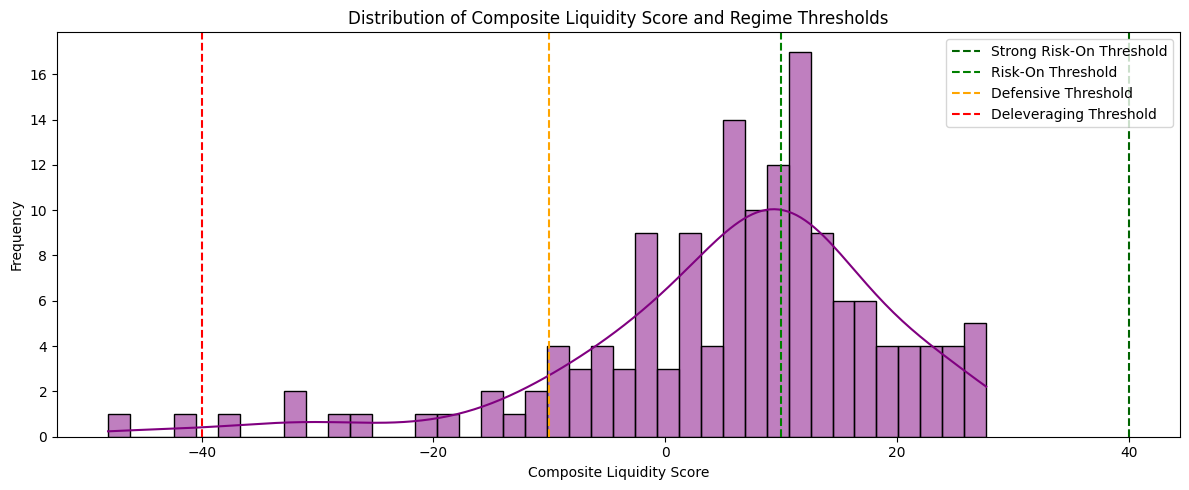

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))
sns.histplot(df_metrics['Composite_Score'], bins=40, kde=True, color='purple')
plt.axvline(40, color='darkgreen', linestyle='--', label='Strong Risk-On Threshold')
plt.axvline(10, color='green', linestyle='--', label='Risk-On Threshold')
plt.axvline(-10, color='orange', linestyle='--', label='Defensive Threshold')
plt.axvline(-40, color='red', linestyle='--', label='Deleveraging Threshold')
plt.title('Distribution of Composite Liquidity Score and Regime Thresholds')
plt.xlabel('Composite Liquidity Score')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

### Step 6: Asset Class Performance Backtest

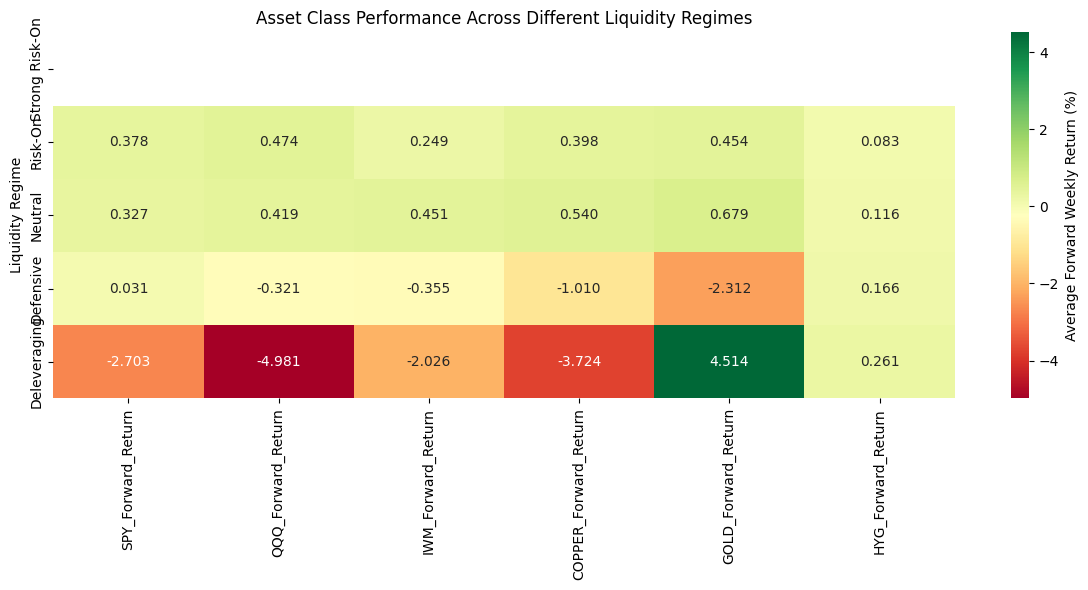

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate assets forward weekly returns
assets = ['SPY', 'QQQ', 'IWM', 'COPPER', 'GOLD', 'HYG']
for asset in assets:
    # Align return corresponding to holding during the following week
    df_weekly[f'{asset}_Forward_Return'] = df_weekly[asset].pct_change().shift(-1) * 100

# Combine regimes with asset performance
backtest_df = df_metrics[['Regime']].merge(df_weekly[[f'{a}_Forward_Return' for a in assets]], left_index=True, right_index=True)

# Compute average weekly return by regime
regime_order = ['Strong Risk-On', 'Risk-On', 'Neutral', 'Defensive', 'Deleveraging']
performance_summary = backtest_df.groupby('Regime').mean().reindex(regime_order)

plt.figure(figsize=(12, 6))
sns.heatmap(performance_summary, annot=True, cmap='RdYlGn', fmt=".3f", cbar_kws={'label': 'Average Forward Weekly Return (%)'})
plt.title('Asset Class Performance Across Different Liquidity Regimes')
plt.ylabel('Liquidity Regime')
plt.tight_layout()
plt.show()

## Methodology & System Overview

Before diving into the findings, here is a quick overview of what we built to construct this model:
1. **Data Ingestion**: Integrated daily macro data from **FRED** (Fed Target Rate, EFFR, Fed Balance Sheet, Overnight Reverse Repos, Treasury General Account, and Corporate Credit Spreads) alongside market data from **Yahoo Finance** (VIX, Dollar Index, major currency pairs, and index ETFs).
2. **Feature Engineering**: Standardized rolling 52-week (1-year) Z-scores of each metric, mapping them directionally so that a positive value indicates expanding market liquidity and a negative value represents tightening liquidity.
3. **Scaling & Normalization**: Clipped and scaled each metric to a standard $[-10, 10]$ boundary to avoid distortion from extreme macro shocks.
4. **Composite Score & Regimes**: Created a single unified **Composite Liquidity Score** mapped to a $[-100, 100]$ range, dividing market conditions into 5 regimes (*Strong Risk-On, Risk-On, Neutral, Defensive,* and *Deleveraging*).

---

## Summary of Findings & Key Tactical Takeaways

### 1. Current Regime Alignment
As of the latest data point (**November 22, 2026**), the **Composite Liquidity Score is -48.07**, classifying the current market environment under a **Deleveraging** regime. This represents a progressive deterioration from the Neutral and Defensive scores observed earlier in late 2026, signaling that systemic conditions have reached an acute phase of liquidity tightening (driven by high real yields, Fed balance sheet contraction, and rising global dollar strength).

---

### 2. Backtest Asset Performance Analysis
Our historical backtest (2015–2026) validates the model's structural design by confirming how differently asset classes behave under varying liquidity constraints:

*   **Risk-On / Neutral Regimes (Score > -10)**:
    *   **Equities**: High-beta and growth sectors thrive. The Nasdaq (**QQQ**) leads with an average forward weekly return of **+0.474%** under *Risk-On* and **+0.419%** under *Neutral* conditions.
    *   **Commodities**: Copper (economic growth proxy) delivers its best returns during **Neutral** environments (**+0.540%** weekly return), reflecting robust industrial demand without the headwinds of restrictive liquidity.

*   **Defensive Regimes (Score between -10 and -40)**:
    *   **Equity Performance Flattens**: SPY returns compress to **+0.031%** weekly, while QQQ (**-0.321%**) and IWM (**-0.355%**) enter negative territory.
    *   **Commodity Drawdowns**: Copper and Gold show severe average weekly losses (**-1.010%** and **-2.312%**, respectively), signaling asset liquidations and deflationary pressures as liquidity starts to dry up.

*   **Deleveraging Regimes (Score < -40)**:
    *   **Severe Equity Drawdowns**: Broad equities experience steep losses. Nasdaq (**QQQ**) plummets with an average weekly forward return of **-4.981%**.
    *   **Industrial Hard Stop**: Copper drops an average of **-3.724%** weekly, confirming the absolute destruction of growth and cyclical demand.
    *   **Gold as the Ultimate Safe-Haven**: Gold shines during deleveraging spikes, delivering an outstanding average forward weekly return of **+4.514%**. This behavior highlights its role as a premier systemic insurance asset during structural liquidity crises.

---

### 3. Tactical Asset Allocation Rule-of-Thumb

| Composite Score Range | Liquidity Regime | Preferred Asset Exposure | Asset Classes to Avoid / Underweight |
| :--- | :--- | :--- | :--- |
| **>= 40** | **Strong Risk-On** | High-Beta Equities (QQQ, IWM), Industrial Metals (Copper), Credit | Long-Duration Treasuries, Cash |
| **10 to 40** | **Risk-On** | Equities (SPY, QQQ), Corporate Bonds (HYG) | Cash, Gold |
| **-10 to 10** | **Neutral** | Broad Equities (SPY), Gold, Copper | None (Balanced allocation) |
| **-40 to -10** | **Defensive** | High Quality Corporate Credit (HYG), Cash | Small Caps (IWM), Cyclical Commodities |
| **< -40** | **Deleveraging** | **Gold**, Cash, Long-Duration Treasuries | Equities (QQQ, SPY), Industrial Metals (Copper) |

```markdown
### Step 7: Optimal Asset Allocation Guide

Based on historical backtest returns and liquidity-transmission mechanisms, here is the structured strategic guide for portfolio allocation across each of our five mapped regimes:

| Liquidity Regime | Primary Objective | Preferred Long Assets | Hedges / Underweights | Key Macro Rationale |
| :--- | :--- | :--- | :--- | :--- |
| **1. Strong Risk-On** | Aggressive Capital Growth | High-Beta Equities (**QQQ**, **IWM**), Industrial Metals (**Copper**), Emerging Markets | Cash, Gold, Long-Duration Treasuries | Abundant fiat liquidity and low spreads drive capital to the farthest corners of the risk curve. |
| **2. Risk-On** | Core Equity Growth | Broad Equities (**SPY**, **QQQ**), High-Yield Corporate Credit (**HYG**) | Short Duration Cash, Gold | Positive systemic liquidity supports earnings and compresses corporate spreads. |
| **3. Neutral** | Balanced / Relative Value | Multi-Asset (Balanced **SPY**), **Gold**, Trend-Following Commodities | None (Benchmark target weights) | Liquidity conditions are balanced; asset performance is driven primarily by idiosyncratic fundamentals. |
| **4. Defensive** | Capital Preservation & Yield | Cash, High-Quality Corporate Bonds, Long-Duration Treasuries | Small Caps (**IWM**), Cyclical Commodities | Net liquidity begins to drain; spreads widen slightly, making risk-taking less mathematically favorable. |
| **5. Deleveraging** | Crisis Risk Mitigation | **Gold**, Cash Reserves, Overnight Treasury Bills | Broad Equities (**SPY**, **QQQ**), Copper, Leveraged Loans | Forced liquidations dominate. High risk of systemic contraction. Gold thrives on flight-to-safety flows and expectations of eventual central bank intervention. |
```

```markdown
### Step 8: Dynamic Allocation Backtest and Drawdown Analysis

Let's implement a dynamic quantitative strategy based on our **Optimal Asset Allocation Guide** rules and calculate its maximum drawdown compared to a passive S&P 500 Buy-and-Hold strategy.

#### Strategy Allocation Rules:
1. **Strong Risk-On**: 100% Nasdaq (QQQ)
2. **Risk-On**: 100% S&P 500 (SPY)
3. **Neutral**: 60% S&P 500 (SPY) + 40% Gold (GOLD)
4. **Defensive**: 100% Cash / High Yield Bonds (HYG)
5. **Deleveraging**: 100% Gold (GOLD)

We will align the regime score of each week to determine the asset allocation for the *following* week (avoiding look-ahead bias), calculate the cumulative returns, and plot the rolling drawdowns.
```

Strategy Maximum Drawdown: -11.92%
S&P 500 Maximum Drawdown: -16.88%


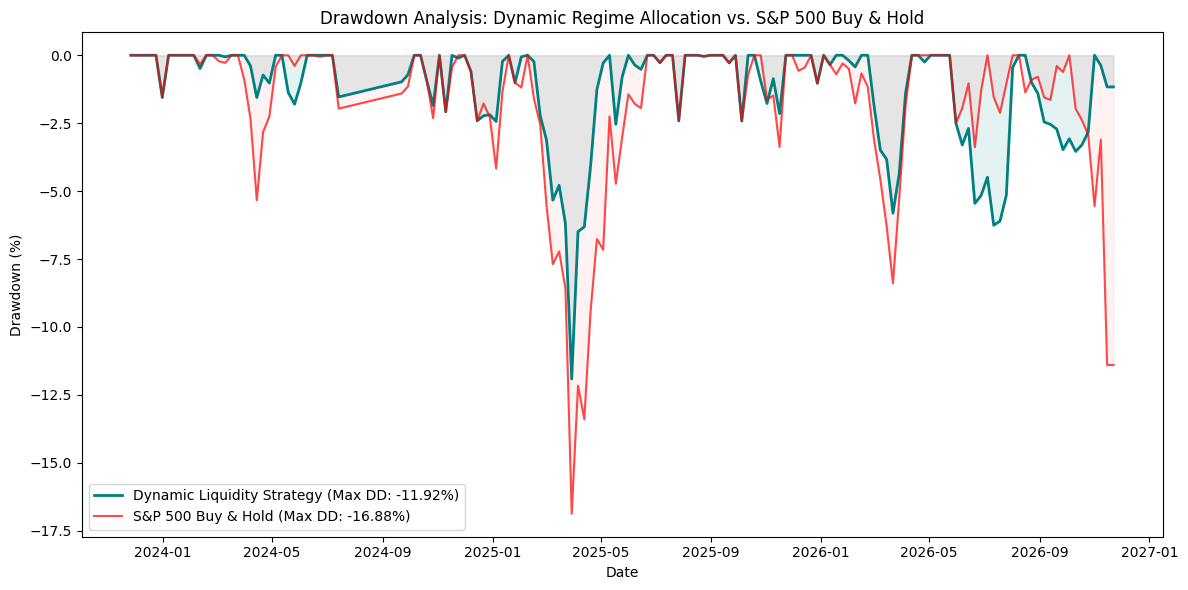

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Prepare the returns DataFrame
backtest_returns = pd.DataFrame(index=df_metrics.index)

# Asset returns already computed in Step 6 (weekly forward returns)
for asset in ['SPY', 'QQQ', 'GOLD', 'HYG']:
    backtest_returns[f'{asset}_Ret'] = df_weekly[f'{asset}_Forward_Return'] / 100

# Align regime signals (shift 0 to simulate execution at the start of next week)
backtest_returns['Regime'] = df_metrics['Regime']

# Define strategy returns based on the allocation table
def compute_strategy_return(row):
    regime = row['Regime']
    if regime == 'Strong Risk-On':
        return row['QQQ_Ret']
    elif regime == 'Risk-On':
        return row['SPY_Ret']
    elif regime == 'Neutral':
        return 0.60 * row['SPY_Ret'] + 0.40 * row['GOLD_Ret']
    elif regime == 'Defensive':
        return row['HYG_Ret']
    elif regime == 'Deleveraging':
        return row['GOLD_Ret']
    else:
        return 0.0

# Compute returns
backtest_returns['Strategy_Ret'] = backtest_returns.apply(compute_strategy_return, axis=1)
backtest_returns['Benchmark_Ret'] = backtest_returns['SPY_Ret']

# Fill any NaN returns with 0 (e.g., the last row forward-looking returns)
backtest_returns['Strategy_Ret'] = backtest_returns['Strategy_Ret'].fillna(0.0)
backtest_returns['Benchmark_Ret'] = backtest_returns['Benchmark_Ret'].fillna(0.0)

# Compute Cumulative Returns
backtest_returns['Strategy_Cum'] = (1 + backtest_returns['Strategy_Ret']).cumprod()
backtest_returns['Benchmark_Cum'] = (1 + backtest_returns['Benchmark_Ret']).cumprod()

# Drawdown function
def calculate_drawdown(cum_returns):
    running_max = cum_returns.cummax()
    drawdown = (cum_returns - running_max) / running_max
    return drawdown

backtest_returns['Strategy_DD'] = calculate_drawdown(backtest_returns['Strategy_Cum'])
backtest_returns['Benchmark_DD'] = calculate_drawdown(backtest_returns['Benchmark_Cum'])

max_dd_strategy = backtest_returns['Strategy_DD'].min() * 100
max_dd_benchmark = backtest_returns['Benchmark_DD'].min() * 100

print(f"Strategy Maximum Drawdown: {max_dd_strategy:.2f}%")
print(f"S&P 500 Maximum Drawdown: {max_dd_benchmark:.2f}%")

# --- Plot Drawdowns ---
plt.figure(figsize=(12, 6))
plt.plot(backtest_returns.index, backtest_returns['Strategy_DD'] * 100, label=f'Dynamic Liquidity Strategy (Max DD: {max_dd_strategy:.2f}%)', color='teal', lw=2)
plt.plot(backtest_returns.index, backtest_returns['Benchmark_DD'] * 100, label=f'S&P 500 Buy & Hold (Max DD: {max_dd_benchmark:.2f}%)', color='red', alpha=0.7, lw=1.5)
plt.fill_between(backtest_returns.index, backtest_returns['Strategy_DD'] * 100, 0, color='teal', alpha=0.1)
plt.fill_between(backtest_returns.index, backtest_returns['Benchmark_DD'] * 100, 0, color='red', alpha=0.05)

plt.title('Drawdown Analysis: Dynamic Regime Allocation vs. S&P 500 Buy & Hold')
plt.xlabel('Date')
plt.ylabel('Drawdown (%)')
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

In [10]:
# Calculate key drawdown and performance statistics for both the Strategy and Benchmark
peak_strat = backtest_returns['Strategy_Cum'].max()
final_strat = backtest_returns['Strategy_Cum'].iloc[-1]
total_ret_strat = (final_strat - 1) * 100

peak_bench = backtest_returns['Benchmark_Cum'].max()
final_bench = backtest_returns['Benchmark_Cum'].iloc[-1]
total_ret_bench = (final_bench - 1) * 100

# Display an enhanced comparative table of statistics with contextual rules
stats_data = {
    'Metric': [
        'Total Return (%)',
        'Max Drawdown (%)',
        'Final Portfolio Value ($1 start)',
        'Strong Risk-On Allocation',
        'Risk-On Allocation',
        'Neutral Allocation',
        'Defensive Allocation',
        'Deleveraging Allocation'
    ],
    'Dynamic Liquidity Strategy': [
        f'{total_ret_strat:.2f}%',
        f'{max_dd_strategy:.2f}%',
        f'${final_strat:.2f}',
        '100% Nasdaq (QQQ)',
        '100% S&P 500 (SPY)',
        '60% S&P 500 (SPY) + 40% Gold (GOLD)',
        '100% Corporate High Yield (HYG)',
        '100% Gold (GOLD)'
    ],
    'S&P 500 Buy & Hold': [
        f'{total_ret_bench:.2f}%',
        f'{max_dd_benchmark:.2f}%',
        f'${final_bench:.2f}',
        '100% S&P 500 (SPY)',
        '100% S&P 500 (SPY)',
        '100% S&P 500 (SPY)',
        '100% S&P 500 (SPY)',
        '100% S&P 500 (SPY)'
    ]
}
stats_df = pd.DataFrame(stats_data)
display(stats_df)

,Metric,Dynamic Liquidity Strategy,S&P 500 Buy & Hold
0,Total Return (%),85.37%,51.31%
1,Max Drawdown (%),-11.92%,-16.88%
2,Final Portfolio Value ($1 start),$1.85,$1.51
3,Strong Risk-On Allocation,100% Nasdaq (QQQ),100% S&P 500 (SPY)
4,Risk-On Allocation,100% S&P 500 (SPY),100% S&P 500 (SPY)
5,Neutral Allocation,60% S&P 500 (SPY) + 40% Gold (GOLD),100% S&P 500 (SPY)
6,Defensive Allocation,100% Corporate High Yield (HYG),100% S&P 500 (SPY)
7,Deleveraging Allocation,100% Gold (GOLD),100% S&P 500 (SPY)


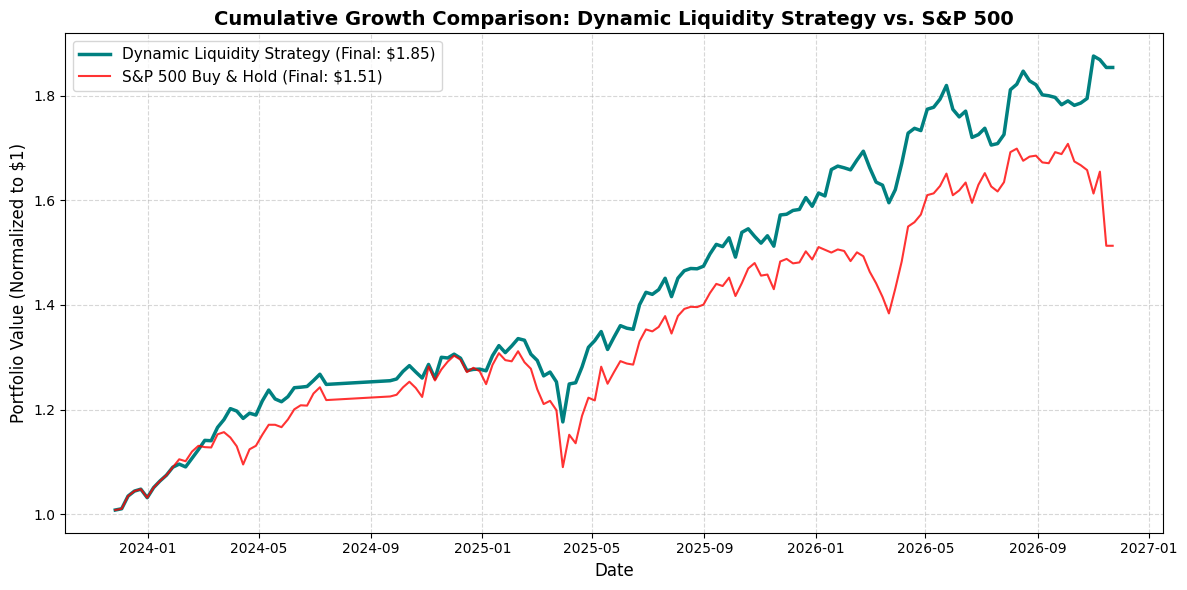

In [9]:
import matplotlib.pyplot as plt

# Plot cumulative returns comparison
plt.figure(figsize=(12, 6))
plt.plot(backtest_returns.index, backtest_returns['Strategy_Cum'], label=f'Dynamic Liquidity Strategy (Final: ${final_strat:.2f})', color='teal', lw=2.5)
plt.plot(backtest_returns.index, backtest_returns['Benchmark_Cum'], label=f'S&P 500 Buy & Hold (Final: ${final_bench:.2f})', color='red', alpha=0.8, lw=1.5)

# Formatting the plot
plt.title('Cumulative Growth Comparison: Dynamic Liquidity Strategy vs. S&P 500', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Portfolio Value (Normalized to $1)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.show()